# 16.16 - Roboflow candidate audit and two-class package

This local research notebook audits the downloaded Roboflow Dental dataset and prepares only the visible-spacing and tooth-malposition classes for a later Kaggle experiment. It does not inspect or package the held-out test split. Source labels are preserved in meaning: gap_or_spacing is broader than midline diastema, and malposition_present is broader than orthodontic crowding.

The source declares CC BY 4.0. Sample photographs contain identifiable faces and phone-interface captures, so this audit notebook is local-only and must not be published with embedded image outputs. The later training package uses the declared public source data with attribution and hashed filenames.

## 1. Load dependencies and identify the immutable source archive

The ZIP stays in data/raw. We record its checksum and use the source README to identify the intended Roboflow version. This also lets us notice metadata inconsistencies before conversion.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib, io, json, re, zipfile
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

ROOT = Path.cwd()
ARCHIVE = ROOT / "data/raw/alignment/Dental.v1-dataset-version-2.yolov8.zip"
assert ARCHIVE.is_file(), ARCHIVE
CLASS_MAP = {6: (0, "gap_or_spacing"), 8: (1, "malposition_present")}
print(f"Archive: {ARCHIVE.name} | {ARCHIVE.stat().st_size:,} bytes")


Archive: Dental.v1-dataset-version-2.yolov8.zip | 753,366,884 bytes


## 2. Verify archive integrity and read source provenance

The package is treated as a version-2 Roboflow export because its downloaded README names Dataset Version 2. The embedded data.yaml points to version 1; we preserve this discrepancy in the audit record and do not silently treat it as resolved.

In [2]:
with zipfile.ZipFile(ARCHIVE) as zf:
    members = [i for i in zf.infolist() if not i.is_dir()]
    member_names = {i.filename for i in members}
    unsafe = [n for n in member_names if n.startswith("/") or ".." in Path(n).parts or "\\" in n]
    assert not unsafe, unsafe[:5]
    archive_crc_error = zf.testzip()
    assert archive_crc_error is None, archive_crc_error
    readme_dataset = zf.read("README.dataset.txt").decode("utf-8", errors="replace")
    readme_roboflow = zf.read("README.roboflow.txt").decode("utf-8", errors="replace")
    source_yaml_text = zf.read("data.yaml").decode("utf-8", errors="replace")
    print("ZIP CRC check:", "passed" if archive_crc_error is None else archive_crc_error)
    print("README version 2:", "Dataset Version 2" in readme_dataset)
    print("README augmentation recipe present:", "augmentation" in readme_roboflow.lower())
    print("Internal data.yaml version line:", re.search(r"version:\s*(\d+)", source_yaml_text).group(1))
    print("Declared license:", re.search(r"license:\s*(.+)", source_yaml_text).group(1))
    print("Source URL:", re.search(r"url:\s*(.+)", source_yaml_text).group(1))
    source_names = eval(re.search(r"names:\s*(\[.*\])", source_yaml_text).group(1))
    print("Source class IDs:", {i: name for i, name in enumerate(source_names)})


ZIP CRC check: passed
README version 2: True
README augmentation recipe present: True
Internal data.yaml version line: 1
Declared license: CC BY 4.0
Source URL: https://universe.roboflow.com/okasha/dental-ktzqf/dataset/1
Source class IDs: {0: 'braces_present', 1: 'crown_present', 2: 'decay_present -large only-', 3: 'existing_veneer_or_bonding', 4: 'extraction_needed', 5: 'fracture_present', 6: 'gap_or_spacing', 7: 'gingival_excess', 8: 'malposition_present', 9: 'severe_discoloration_present', 10: 'tooth_missing'}


## 3. Audit train and validation annotations only

We retain the source train/validation assignment and group images by their shared source filename stem. Augmented views from one source image stay within one split. The test directory is deliberately excluded from this cell and all later cells.

In [3]:
records = []
box_counts = Counter()
image_counts = Counter()
source_groups = defaultdict(set)
missing_labels = Counter()
empty_labels = Counter()
invalid_boxes = Counter()
with zipfile.ZipFile(ARCHIVE) as zf:
    names = set(zf.namelist())
    for split in ("train", "valid"):
        image_names = sorted(n for n in names if n.startswith(f"{split}/images/") and Path(n).suffix.lower() in {".jpg", ".jpeg", ".png"})
        for image_name in image_names:
            p = Path(image_name)
            label_name = f"{split}/labels/{p.stem}.txt"
            image_counts[split] += 1
            if label_name not in names:
                missing_labels[split] += 1
                continue
            rows = []
            text = zf.read(label_name).decode("utf-8", errors="replace").strip()
            if not text:
                empty_labels[split] += 1
            for line in text.splitlines():
                values = line.split()
                if len(values) != 5:
                    invalid_boxes[split] += 1
                    continue
                cls = int(values[0]); x, y, w, h = map(float, values[1:])
                if cls < 0 or cls >= len(source_names) or not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1) or x-w/2 < 0 or y-h/2 < 0 or x+w/2 > 1 or y+h/2 > 1:
                    invalid_boxes[split] += 1
                if cls in CLASS_MAP:
                    box_counts[(split, cls)] += 1
                rows.append((cls, x, y, w, h))
            canonical = p.stem.split("_jpg.rf.")[0]
            group_id = hashlib.sha256(canonical.encode()).hexdigest()[:20]
            source_groups[split].add(group_id)
            present = {cls for cls, *_ in rows}
            records.append({"split": split, "member": image_name, "label_member": label_name, "group_id": group_id, "source_id": p.stem, "image_suffix": p.suffix.lower(), "target_boxes": sum(cls in CLASS_MAP for cls, *_ in rows), "gap_or_spacing_boxes": sum(cls == 6 for cls, *_ in rows), "malposition_boxes": sum(cls == 8 for cls, *_ in rows), "gap_or_spacing_present": 6 in present, "malposition_present": 8 in present, "rows": rows})

manifest = pd.DataFrame([{k:v for k,v in r.items() if k != "rows"} for r in records])
assert missing_labels == Counter(), dict(missing_labels)
assert invalid_boxes == Counter(), dict(invalid_boxes)
assert set(manifest.split) == {"train", "valid"}
assert not (source_groups["train"] & source_groups["valid"]), "Source filename groups cross splits"
print("Image counts:", dict(image_counts))
print("Unique source filename groups:", {k: len(v) for k,v in source_groups.items()})
print("Missing label files:", dict(missing_labels))
print("Empty train/validation label files:", dict(empty_labels))
print("Invalid YOLO rows/geometry:", dict(invalid_boxes))
print("Train/validation source-group overlap:", len(source_groups["train"] & source_groups["valid"]))
display(manifest.groupby("split")[['gap_or_spacing_boxes','malposition_boxes','gap_or_spacing_present','malposition_present']].sum())


Image counts: {'train': 15034, 'valid': 477}
Unique source filename groups: {'train': 3818, 'valid': 477}
Missing label files: {}
Empty train/validation label files: {'train': 15}
Invalid YOLO rows/geometry: {}
Train/validation source-group overlap: 0


,gap_or_spacing_boxes,malposition_boxes,gap_or_spacing_present,malposition_present
split,,,,
train,8225,4161,4783,2608
valid,215,149,150,92


## 4. Inspect class balance, source-group augmentation, and box geometry

The source export includes pre-generated augmentations in train. We report the number of augmented files per source group so their repeated contribution is visible. No new labels are inferred from an absent target box.

Train/validation images per source group:


,split,count,min,median,max
0,train,3818,3,3.0,9
1,valid,477,1,1.0,1


,split,class,boxes,source_images
0,train,gap_or_spacing,8225,1214
1,train,malposition_present,4161,659
2,valid,gap_or_spacing,215,150
3,valid,malposition_present,149,92


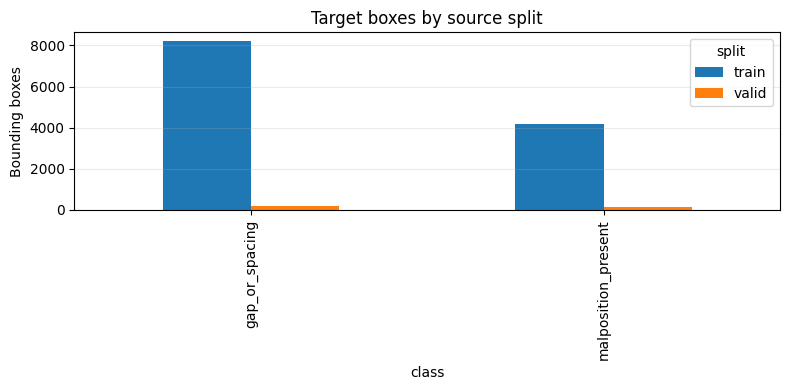

In [4]:
group_sizes = manifest.groupby(["split", "group_id"]).size().rename("images_per_source").reset_index()
summary = group_sizes.groupby("split")["images_per_source"].agg(["count", "min", "median", "max"]).reset_index()
print("Train/validation images per source group:")
display(summary)

class_summary = pd.DataFrame([
    {"split": split, "class": name, "boxes": box_counts[(split, cls)], "source_images": int(manifest.loc[(manifest.split==split) & manifest["gap_or_spacing_present" if cls == 6 else "malposition_present"], "group_id"].nunique())}
    for split in ("train", "valid") for cls, (new_id, name) in CLASS_MAP.items()
])
display(class_summary)
ax = class_summary.pivot(index="class", columns="split", values="boxes").plot(kind="bar", figsize=(8,4), title="Target boxes by source split")
ax.set_ylabel("Bounding boxes"); ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()


## 5. Visually inspect representative source boxes

The following local-only gallery shows source annotations for the two selected classes in both splits. Green boxes denote gap_or_spacing; red boxes denote malposition_present. This is a label-quality review, not clinical adjudication. Keep this notebook and its image outputs local-only.

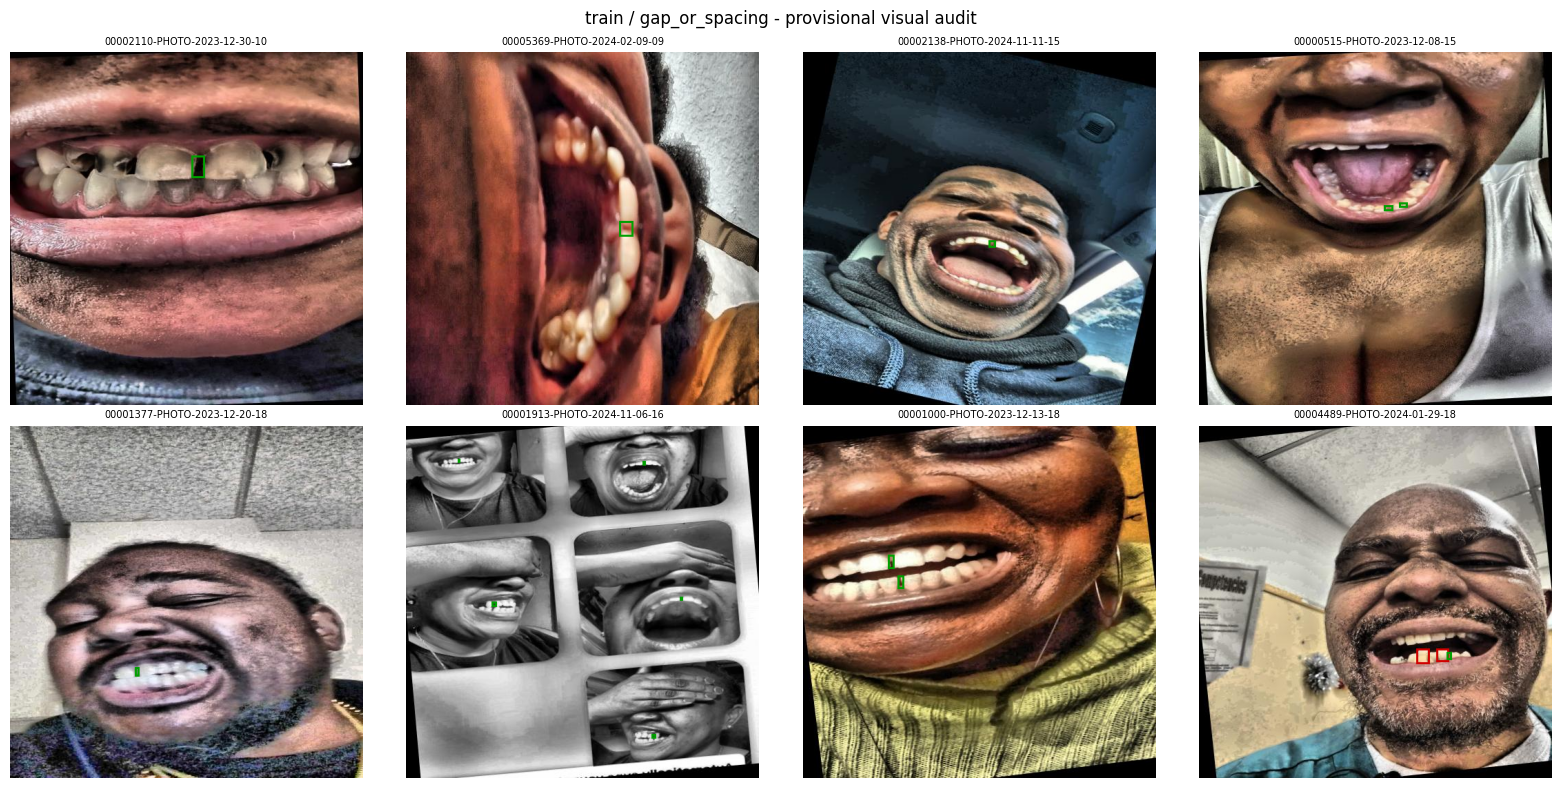

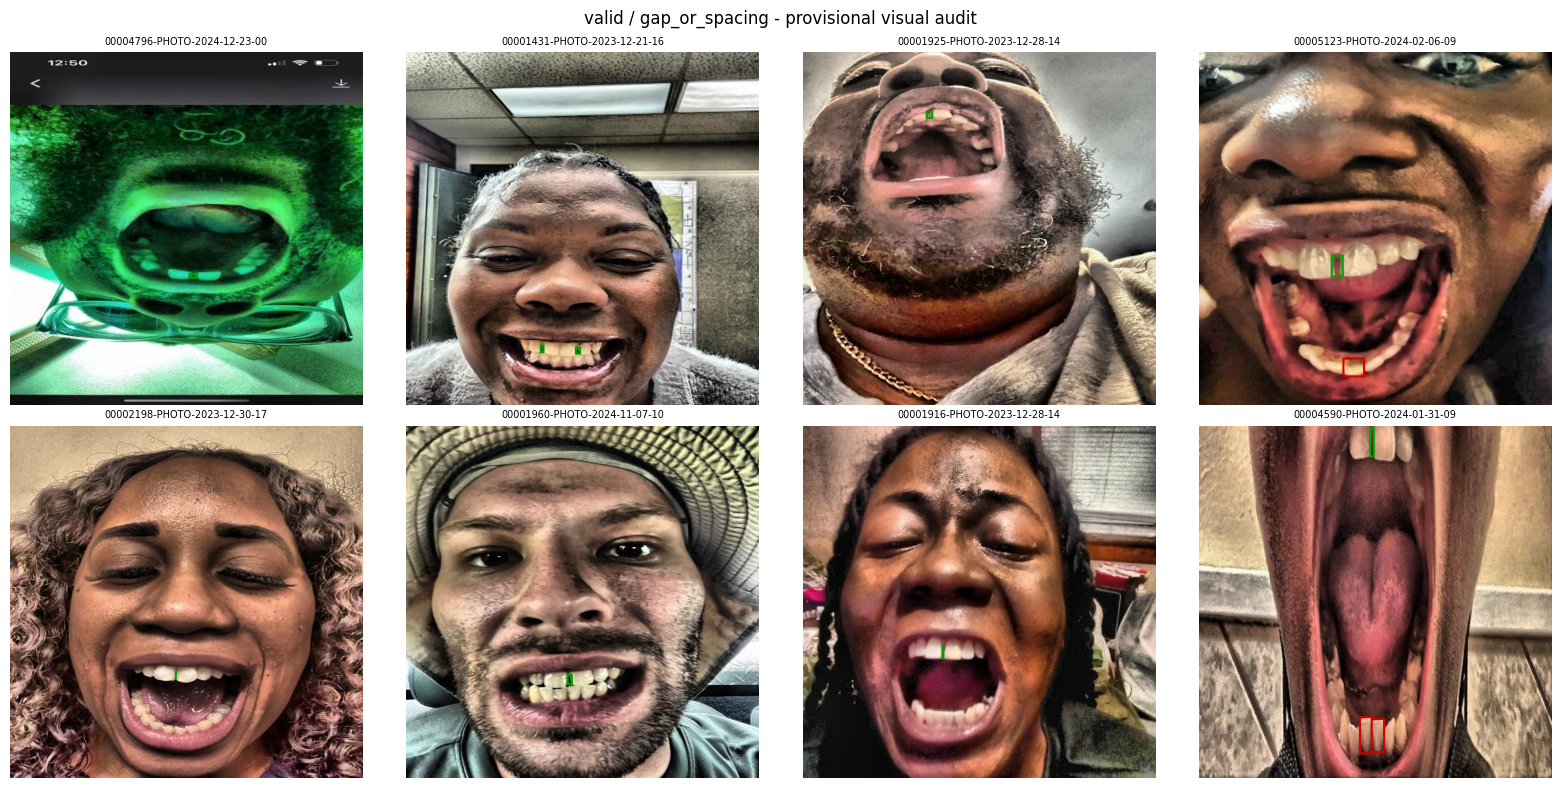

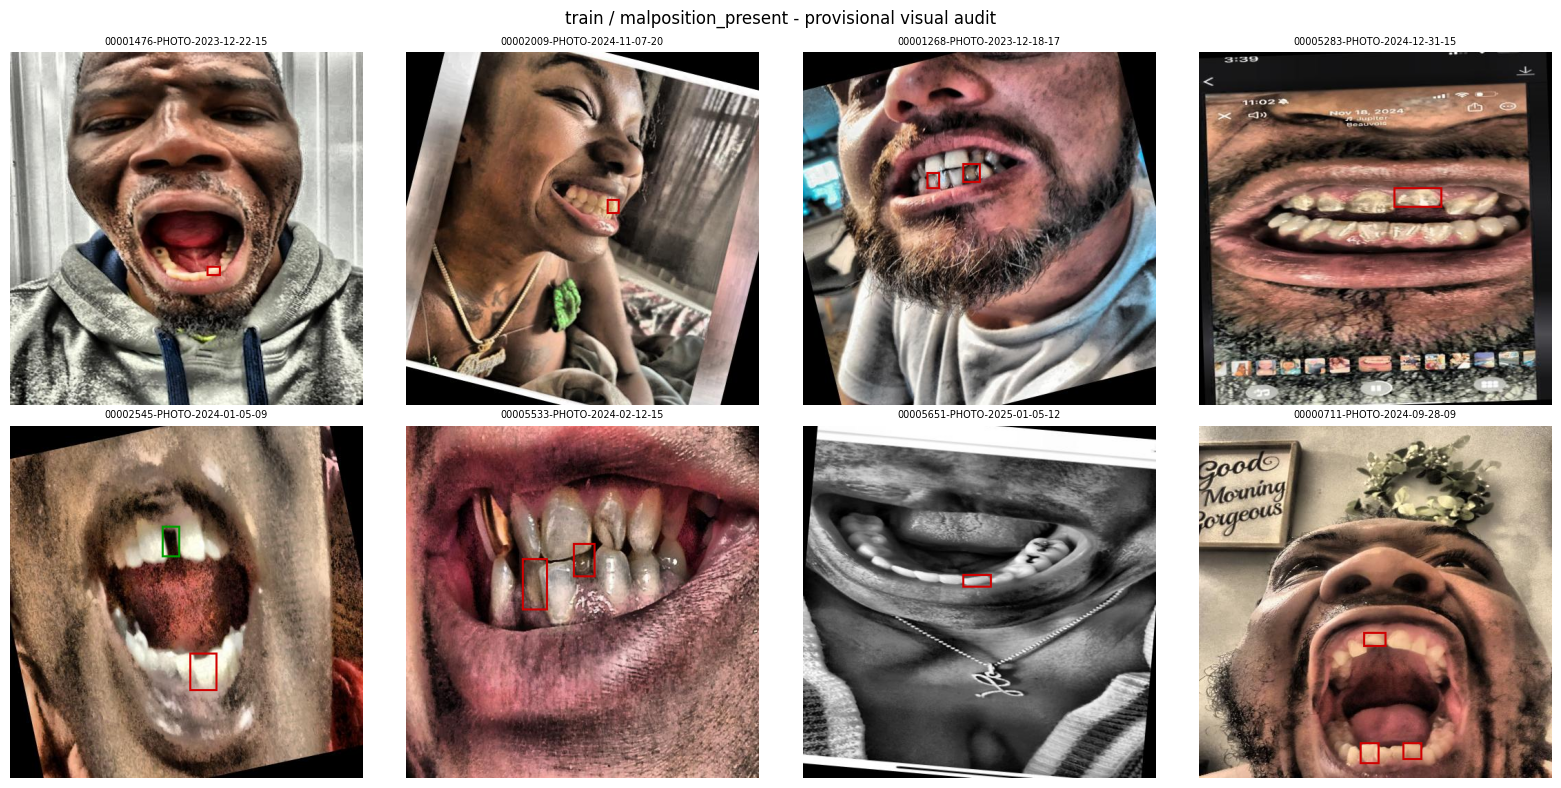

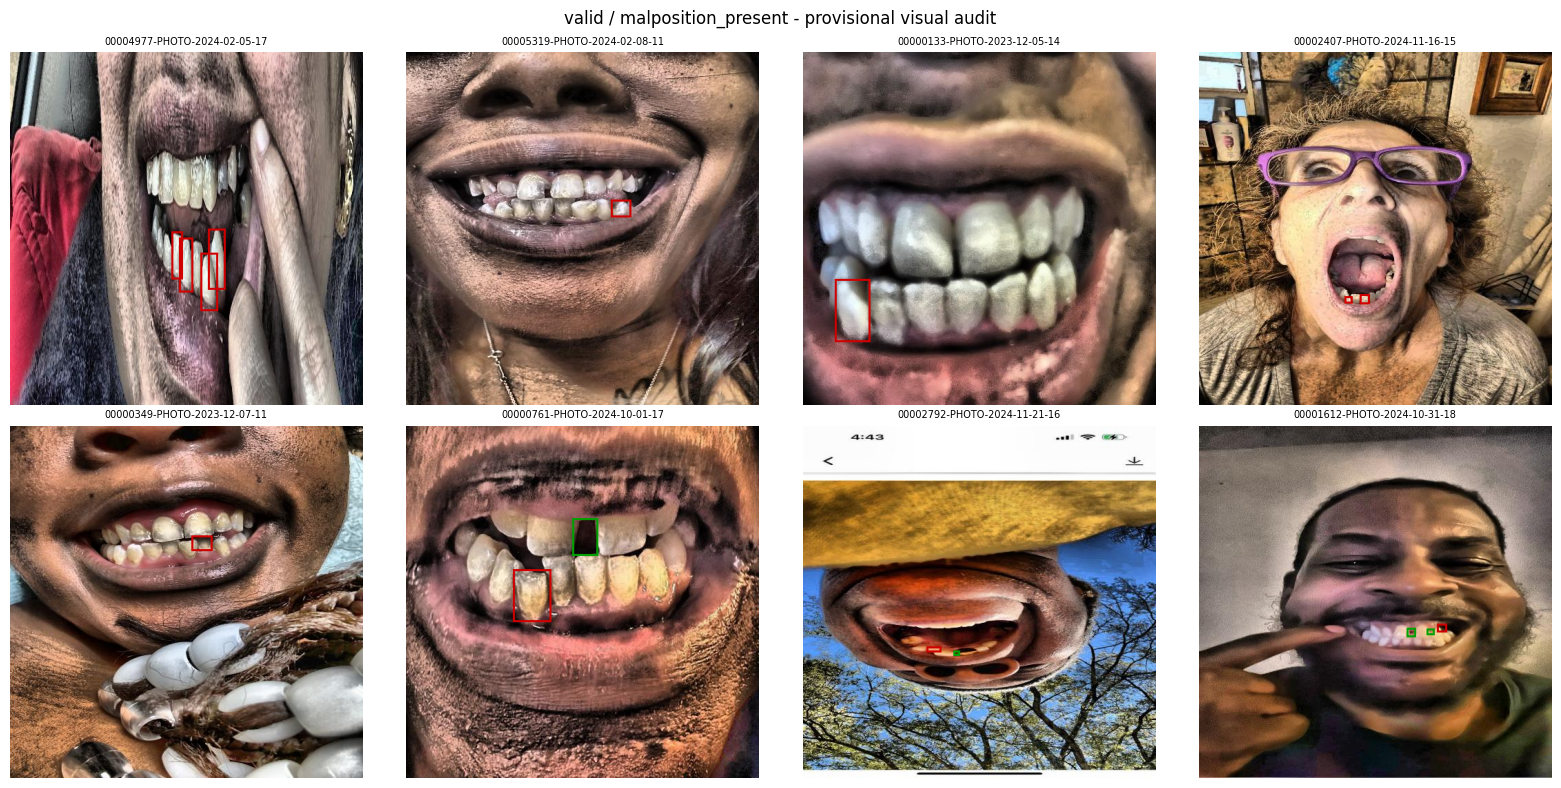

In [5]:
def show_target_gallery(split, cls_id, count=8, seed=51324):
    candidates = [r for r in records if r["split"] == split and any(row[0] == cls_id for row in r["rows"])]
    rng = __import__("random").Random(seed + cls_id + (0 if split == "train" else 1))
    rng.shuffle(candidates)
    chosen = candidates[:count]
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    with zipfile.ZipFile(ARCHIVE) as zf:
        for ax, row in zip(axes.flat, chosen):
            image = Image.open(io.BytesIO(zf.read(row["member"]))).convert("RGB")
            draw = ImageDraw.Draw(image)
            for c, x, y, w, h in row["rows"]:
                if c not in CLASS_MAP: continue
                color = "#00a000" if c == 6 else "#d00000"
                draw.rectangle(((x-w/2)*image.width, (y-h/2)*image.height, (x+w/2)*image.width, (y+h/2)*image.height), outline=color, width=3)
            ax.imshow(image); ax.axis("off"); ax.set_title(row["source_id"][:28], fontsize=7)
    fig.suptitle(f"{split} / {source_names[cls_id]} - provisional visual audit")
    plt.tight_layout(); plt.show()

show_target_gallery("train", 6)
show_target_gallery("valid", 6)
show_target_gallery("train", 8)
show_target_gallery("valid", 8)


## 6. Prepare a reproducible two-class train/validation package

The converter preserves source train/validation groups, strips source timestamps from filenames, hashes source-group identifiers, maps source class 6 to output class 0 and source class 8 to output class 1, and omits all other classes. It intentionally excludes the test directory. Original images are retained without further augmentation so the Kaggle experiments can use one controlled augmentation policy.

In [6]:
from zipfile import ZIP_DEFLATED
from hashlib import sha256
from csv import DictWriter

OUT = ROOT / "data/processed/alignment_visible_v2"
OUT.mkdir(parents=True, exist_ok=True)
PACKAGE = OUT / "alignment_visible_v2_train_valid.zip"
MANIFEST_PATH = ROOT / "data/manifests/alignment_visible_v2_manifest.csv"
MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
manifest_rows = []

def digest(data): return sha256(data).hexdigest()

with zipfile.ZipFile(ARCHIVE) as source_zip, zipfile.ZipFile(PACKAGE, "w", compression=ZIP_DEFLATED, compresslevel=1) as out_zip:
    for row in records:
        image_bytes = source_zip.read(row["member"])
        source_label = source_zip.read(row["label_member"]).decode("utf-8", errors="replace").strip()
        image_hash = digest(image_bytes)
        anon_id = digest((row["split"] + "/" + row["member"]).encode())[:24]
        group_id = row["group_id"]
        suffix = row["image_suffix"]
        image_rel = f"{row['split']}/images/{anon_id}{suffix}"
        label_rel = f"{row['split']}/labels/{anon_id}.txt"
        converted = []
        for line in source_label.splitlines() if source_label else []:
            cls, x, y, w, h = line.split()
            old_cls = int(cls)
            if old_cls in CLASS_MAP:
                new_cls = CLASS_MAP[old_cls][0]
                converted.append(f"{new_cls} {x} {y} {w} {h}")
        label_bytes = ("\n".join(converted) + ("\n" if converted else "")).encode()
        out_zip.writestr(image_rel, image_bytes)
        out_zip.writestr(label_rel, label_bytes)
        manifest_rows.append({"sample_id": anon_id, "split": row["split"], "group_id_sha256_20": group_id, "image": image_rel, "label": label_rel, "image_sha256": image_hash, "label_sha256": digest(label_bytes), "gap_or_spacing_boxes": row["gap_or_spacing_boxes"], "malposition_boxes": row["malposition_boxes"], "target_boxes": row["target_boxes"]})
    data_yaml = "path: .\ntrain: train/images\nval: valid/images\nnames:\n  0: gap_or_spacing\n  1: malposition_present\n"
    out_zip.writestr("data.yaml", data_yaml)
    attribution = """# Dataset attribution

Source: Dental - Dataset Version 2, by Okashas Workspace, Roboflow Universe.
Source page: https://universe.roboflow.com/okasha/dental-ktzqf
Declared license: Creative Commons Attribution 4.0 International (CC BY 4.0).

This prepared package retains source train and validation images only. It keeps classes gap_or_spacing and malposition_present, renumbered as 0 and 1, and excludes the source test split. Other source classes and their boxes are omitted. No clinical relabeling is claimed.
"""
    out_zip.writestr("ATTRIBUTION.md", attribution)
    import csv, io
    manifest_buffer = io.StringIO(newline="")
    manifest_writer = csv.DictWriter(manifest_buffer, fieldnames=list(manifest_rows[0]))
    manifest_writer.writeheader(); manifest_writer.writerows(manifest_rows)
    out_zip.writestr("manifest.csv", manifest_buffer.getvalue())
    train_count = sum(r["split"] == "train" for r in manifest_rows)
    valid_count = sum(r["split"] == "valid" for r in manifest_rows)
    train_groups = manifest[manifest.split == "train"].group_id.nunique()
    valid_groups = manifest[manifest.split == "valid"].group_id.nunique()
    gap_train = box_counts[("train", 6)]; gap_valid = box_counts[("valid", 6)]
    mal_train = box_counts[("train", 8)]; mal_valid = box_counts[("valid", 8)]
    data_card = f"""# DentalSelfie Visible Alignment Dataset - v2 prepared subset

Source: Dental - Dataset Version 2, Okashas Workspace, Roboflow Universe.
URL: https://universe.roboflow.com/okasha/dental-ktzqf
Declared source license: CC BY 4.0. Attribute the source author and link when redistributing.

## Included data

- Train: {train_count:,} image views from {train_groups:,} filename-derived source groups.
- Validation: {valid_count:,} images from {valid_groups:,} filename-derived source groups.
- Held-out test data is intentionally excluded from this package.
- Source classes retained: gap_or_spacing (source class 6, output class 0) and malposition_present (source class 8, output class 1).
- Source target boxes: train gap_or_spacing={gap_train:,}, malposition_present={mal_train:,}; validation gap_or_spacing={gap_valid:,}, malposition_present={mal_valid:,}.
- Filenames and source group identifiers are replaced with hashes; image pixels and source bounding boxes are retained.

## Label semantics and limitations

These are the source dataset's broad visual labels. gap_or_spacing is not restricted to a midline diastema, and malposition_present is not equivalent to a clinician-confirmed crowding diagnosis. No clinical relabeling or clinician review is claimed. Images without a retained target box are treated as background for the two retained classes; incomplete source annotations may therefore introduce false-negative background examples. Filename grouping prevents augmented copies of one source filename from crossing train/validation, but the source provides no patient IDs, so patient-level independence is not established.

The source describes augmentations and a 4,773-image parent set. The downloaded archive README says Dataset Version 2, while its embedded data.yaml points to version 1 and its reported image total differs from the members in the archive. The archive itself is retained locally with SHA-256 in the project audit notebook; the discrepancy is documented and unresolved.

The source photographs can include identifiable faces and phone-interface screenshots. This is a publicly listed CC BY 4.0 source; the prepared package preserves the source attribution. These images are research data and are not clinical diagnoses.
"""
    out_zip.writestr("DATA_CARD.md", data_card)

with MANIFEST_PATH.open("w", newline="", encoding="utf-8") as f:
    writer = DictWriter(f, fieldnames=list(manifest_rows[0]))
    writer.writeheader(); writer.writerows(manifest_rows)
print("Prepared archive:", PACKAGE, f"({PACKAGE.stat().st_size:,} bytes)")
print("Manifest:", MANIFEST_PATH, f"({len(manifest_rows):,} rows)")


Prepared archive: C:\Users\huynh\Desktop\oral-disease\data\processed\alignment_visible_v2\alignment_visible_v2_train_valid.zip (720,767,609 bytes)
Manifest: C:\Users\huynh\Desktop\oral-disease\data\manifests\alignment_visible_v2_manifest.csv (15,511 rows)


## 7. Verify the prepared package and record its fingerprints

Before upload, verify that every packaged image has a label file, every class ID is 0 or 1, split groups remain separate, and no test path appears. These are deterministic package-integrity checks, not model results.

In [7]:
with zipfile.ZipFile(PACKAGE) as zf:
    package_names = set(zf.namelist())
    assert not any(name.startswith("test/") for name in package_names)
    assert {"data.yaml", "ATTRIBUTION.md"} <= package_names
    package_images = [n for n in package_names if "/images/" in n]
    package_labels = [n for n in package_names if "/labels/" in n]
    assert len(package_images) == len(package_labels) == len(manifest_rows)
    package_bad = []
    for label_name in package_labels:
        for line in zf.read(label_name).decode().splitlines():
            parts = line.split()
            if len(parts) != 5 or int(parts[0]) not in (0, 1): package_bad.append(label_name)
    assert not package_bad, package_bad[:5]
    package_crc_error = zf.testzip()
    assert package_crc_error is None, package_crc_error
assert not (manifest.groupby("group_id").split.nunique() > 1).any()
print("Packaged images/labels:", len(package_images), len(package_labels))
print("Test paths in package:", sum(n.startswith("test/") for n in package_names))
print("Output class map:", {0: "gap_or_spacing", 1: "malposition_present"})
print("Package SHA-256:", digest(PACKAGE.read_bytes()))
print("Manifest SHA-256:", digest(MANIFEST_PATH.read_bytes()))


Packaged images/labels: 15511 15511
Test paths in package: 0
Output class map: {0: 'gap_or_spacing', 1: 'malposition_present'}


Package SHA-256: 32c344cf993b9d4c48d452d78de63359325a2cccfeba6f04bb565c1052ff5f25
Manifest SHA-256: 38cba07194707131b629b020ea9078d487dd397e13221d88075ca8d9cf7a3e9b


## 8. Decision and limitations

This candidate provides enough source annotations for a bounded two-class YOLO experiment, and its train/validation files are source-group separated by the available filename-derived key. It is not a patient-independent split because patient IDs are absent. The source class gap_or_spacing is broader than midline diastema; malposition_present is broader than crowding. The dataset contains phone-style photographs and screenshots; high identity variation, framing, and annotation completeness remain risks. Treat validation metrics as exploratory and do not open or use the held-out test split in this stage.

The training plan uses YOLO11n as the baseline, YOLO11s as a matched capacity comparison, and the existing occlusal YOLO11n checkpoint as an exploratory cross-view initialization. A cross-view result is a transfer experiment, not a replication of the 2026 paper.